In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("E:\\archive (1)\\stocks\AAPL.csv")

In [3]:
df.shape

(9909, 7)

In [4]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400


In [5]:
df.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.dtypes

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9909 entries, 0 to 9908
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       9909 non-null   object 
 1   Open       9909 non-null   float64
 2   High       9909 non-null   float64
 3   Low        9909 non-null   float64
 4   Close      9909 non-null   float64
 5   Adj Close  9909 non-null   float64
 6   Volume     9909 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 542.0+ KB


In [9]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [10]:
df["Date"].dtype

dtype('<M8[ns]')

In [11]:
df["Date"].isna().sum()

0

In [12]:
df["Date"].min()

Timestamp('1980-12-12 00:00:00')

In [13]:
df["Date"].max()

Timestamp('2020-04-01 00:00:00')

In [14]:
df.dtypes

Date         datetime64[ns]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object

In [15]:
price_columns = ["Open", "High", "Low", "Close", "Adj Close"]

In [16]:
(df[price_columns] <= 0).sum()

Open         0
High         0
Low          0
Close        0
Adj Close    0
dtype: int64

In [17]:
(df["Volume"] < 0).sum()

0

In [18]:
(df["High"] < df["Low"]).sum()

0

In [19]:
(df["Open"] > df["High"]).sum()

0

In [20]:
(df["Open"] < df["Low"]).sum()

0

In [21]:
(df["Close"] > df["High"]).sum()

0

In [22]:
(df["Close"] < df["Low"]).sum()

0

In [23]:
df = df.sort_values("Date").reset_index(drop=True)

In [24]:
df.shape

(9909, 7)

In [25]:
df["Date"].is_monotonic_increasing

True

In [26]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400


In [27]:
import matplotlib.pyplot as plt

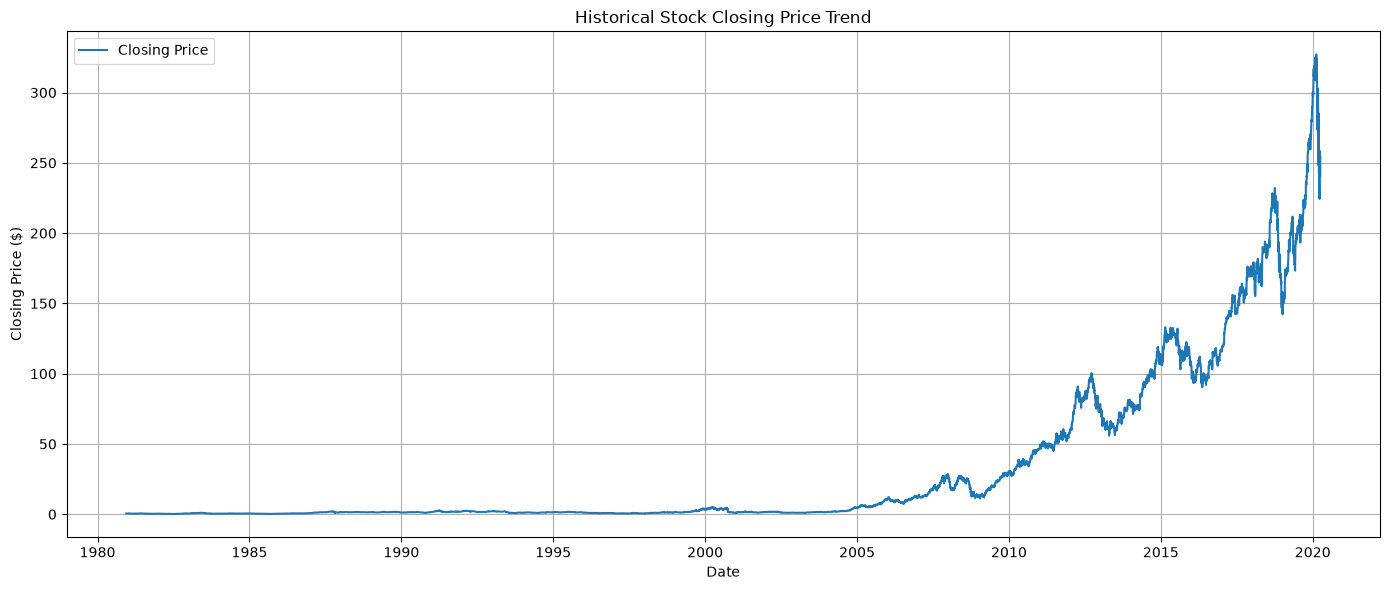

In [28]:
plt.figure(figsize=(14, 6))
plt.plot(df["Date"], df["Close"], label="Closing Price")
plt.title("Historical Stock Closing Price Trend")
plt.xlabel("Date")
plt.ylabel("Closing Price ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

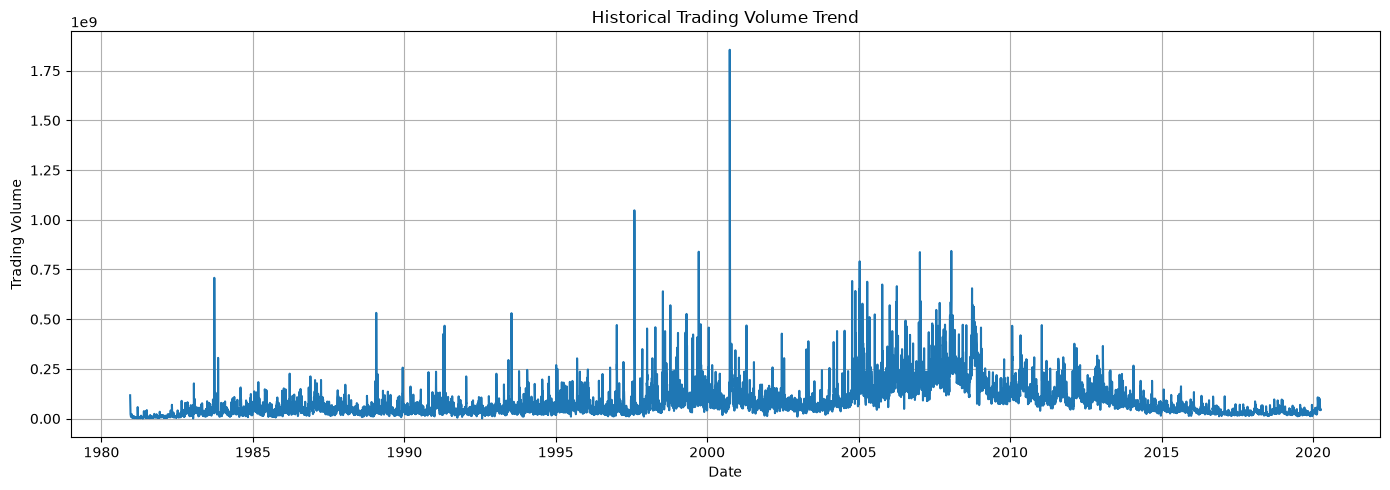

In [29]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Volume"])
plt.title("Historical Trading Volume Trend")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.grid(True)
plt.tight_layout()
plt.show()


In [30]:
df["Daily_Return"] = df["Close"].pct_change() * 100

In [31]:
display(df["Daily_Return"].describe())

count    9908.000000
mean        0.104133
std         2.873774
min       -51.869158
25%        -1.331956
50%         0.000000
75%         1.474450
max        33.227849
Name: Daily_Return, dtype: float64

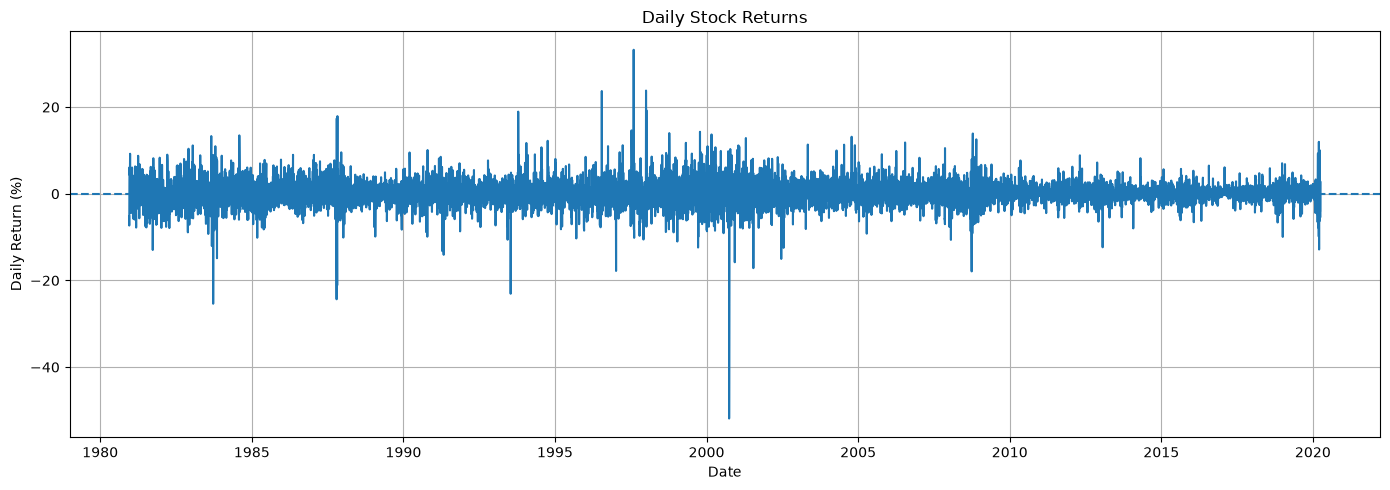

In [32]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Daily_Return"])
plt.axhline(y=0, linestyle="--")
plt.title("Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
df["MA_5"] = df["Close"].rolling(window=5).mean()
df["MA_10"] = df["Close"].rolling(window=10).mean()
df["MA_20"] = df["Close"].rolling(window=20).mean()

In [34]:
df[["Date", "Close", "MA_5", "MA_10", "MA_20"]].tail(10)

,Date,Close,MA_5,MA_10,MA_20
9899,2020-03-19,244.779999,252.898001,262.869000,277.565997
9900,2020-03-20,229.240005,243.152002,256.890001,273.375498
9901,2020-03-23,224.369995,239.584000,252.709999,269.684998
9902,2020-03-24,246.880005,238.388000,248.864000,267.624999
9903,2020-03-25,245.520004,238.158002,245.873001,265.268500
9904,2020-03-26,258.440002,240.890002,246.894002,264.514500
9905,2020-03-27,247.740005,244.590002,243.871002,263.233501
9906,2020-03-30,254.809998,250.678003,245.131001,261.033501
9907,2020-03-31,254.289993,252.160001,245.274001,259.282001
9908,2020-04-01,240.910004,251.238000,244.698001,256.190501


In [35]:
delta = df["Close"].diff()

In [36]:
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

In [37]:
avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

In [38]:
rs = avg_gain / avg_loss
df["RSI_14"] = 100 - (100 / (1 + rs))

In [39]:
df.loc[(avg_loss == 0) & (avg_gain > 0), "RSI_14"] = 100
df.loc[(avg_loss == 0) & (avg_gain == 0), "RSI_14"] = 50

In [40]:
df[["Date", "Close", "RSI_14"]].tail(10)

,Date,Close,RSI_14
9899,2020-03-19,244.779999,43.661286
9900,2020-03-20,229.240005,33.860711
9901,2020-03-23,224.369995,34.602430
9902,2020-03-24,246.880005,37.304547
9903,2020-03-25,245.520004,38.796443
9904,2020-03-26,258.440002,43.065694
9905,2020-03-27,247.740005,45.578425
9906,2020-03-30,254.809998,42.224034
9907,2020-03-31,254.289993,44.345175
9908,2020-04-01,240.910004,47.885617


In [41]:
df["Next_Close"] = df["Close"].shift(-1)

In [42]:
df["Target"] = (df["Next_Close"] > df["Close"]).astype(int)

In [43]:
df.loc[df["Next_Close"].isna(), "Target"] = float("nan")

In [44]:
df[["Date", "Close", "Next_Close", "Target"]].tail(10)

,Date,Close,Next_Close,Target
9899,2020-03-19,244.779999,229.240005,0.0
9900,2020-03-20,229.240005,224.369995,0.0
9901,2020-03-23,224.369995,246.880005,1.0
9902,2020-03-24,246.880005,245.520004,0.0
9903,2020-03-25,245.520004,258.440002,1.0
9904,2020-03-26,258.440002,247.740005,0.0
9905,2020-03-27,247.740005,254.809998,1.0
9906,2020-03-30,254.809998,254.289993,0.0
9907,2020-03-31,254.289993,240.910004,0.0
9908,2020-04-01,240.910004,NaN,NaN


In [45]:
df["Target"].value_counts(dropna=False)

Target
0.0    5018
1.0    4890
NaN       1
Name: count, dtype: int64

In [46]:
df["Daily_Return"] = df["Close"].pct_change() * 100

In [47]:
features = ["Daily_Return",
    "MA_5",
    "MA_10",
    "MA_20",
    "RSI_14"]

In [48]:
df[features].isnull().sum()

Daily_Return     1
MA_5             4
MA_10            9
MA_20           19
RSI_14          14
dtype: int64

In [49]:
df["Target"].value_counts(dropna=False)

Target
0.0    5018
1.0    4890
NaN       1
Name: count, dtype: int64

In [50]:
from sklearn.model_selection import train_test_split

In [51]:
feature_columns = ["Daily_Return",
    "MA_5",
    "MA_10",
    "MA_20",
    "RSI_14"]

In [52]:
model_df = df.dropna(subset=feature_columns + ["Target"]).copy()

In [53]:
X = model_df[feature_columns]
y = model_df["Target"].astype(int)

In [54]:
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [55]:
len(X_train)

7911

In [56]:
len(X_test)

1978

In [57]:
model_df["Date"].iloc[0], "to", model_df["Date"].iloc[split_index - 1]

(Timestamp('1981-01-12 00:00:00'), 'to', Timestamp('2012-05-18 00:00:00'))

In [58]:
model_df["Date"].iloc[split_index], "to", model_df["Date"].iloc[-1]

(Timestamp('2012-05-21 00:00:00'), 'to', Timestamp('2020-03-31 00:00:00'))

In [59]:
y_train.value_counts()

Target
0    4061
1    3850
Name: count, dtype: int64

In [60]:
y_test.value_counts()

Target
1    1030
0     948
Name: count, dtype: int64

In [61]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

print("\nChronological split valid:",
      model_df["Date"].iloc[split_index - 1]
      < model_df["Date"].iloc[split_index])


Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0

Chronological split valid: True


In [62]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [63]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42))

In [64]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Daily_Return','MA_5','MA_10','MA_20','RSI_14']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [65]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1)

In [66]:
random_forest_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [67]:
y_pred_lr = logistic_model.predict(X_test)
y_pred_rf = random_forest_model.predict(X_test)

In [68]:
y_pred_lr[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [69]:
y_pred_rf[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1])

In [70]:
y_test.iloc[:20].to_list()

[0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1]

In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score)

In [72]:
results = []

for name, model, predictions in [
    ("Logistic Regression", logistic_model, y_pred_lr),
    ("Random Forest", random_forest_model, y_pred_rf)]:
    
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({"Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)})

In [73]:
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5207,0.5207,1.0000,0.6848,0.5125
1,Random Forest,0.4772,0.4947,0.1806,0.2646,0.5010


In [74]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

In [75]:
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])

print("Logistic Regression Confusion Matrix:")
print(cm_lr)


Logistic Regression Confusion Matrix:
[[   0  948]
 [   0 1030]]


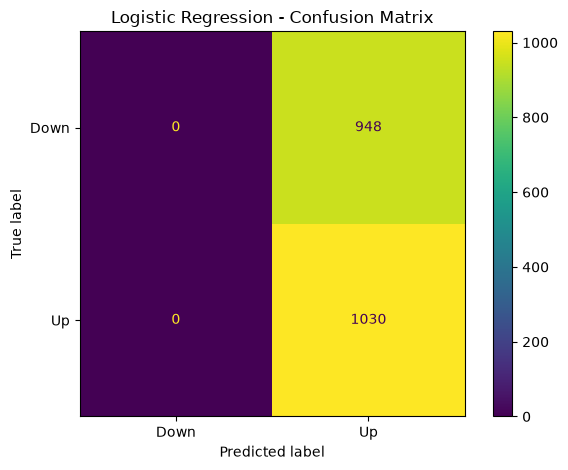

In [76]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Down", "Up"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [77]:
print(classification_report(
    y_test, y_pred_lr,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))

              precision    recall  f1-score   support

        Down       0.00      0.00      0.00       948
          Up       0.52      1.00      0.68      1030

    accuracy                           0.52      1978
   macro avg       0.26      0.50      0.34      1978
weighted avg       0.27      0.52      0.36      1978



Random Forest Confusion Matrix:
[[758 190]
 [844 186]]


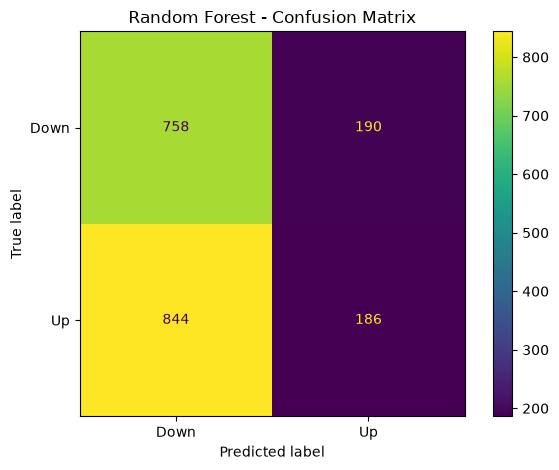

In [78]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

print("Random Forest Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Down", "Up"]
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [79]:
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

        Down       0.47      0.80      0.59       948
          Up       0.49      0.18      0.26      1030

    accuracy                           0.48      1978
   macro avg       0.48      0.49      0.43      1978
weighted avg       0.48      0.48      0.42      1978



In [80]:
comparison = pd.DataFrame({
    "Date": model_df["Date"].iloc[split_index:].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf
})


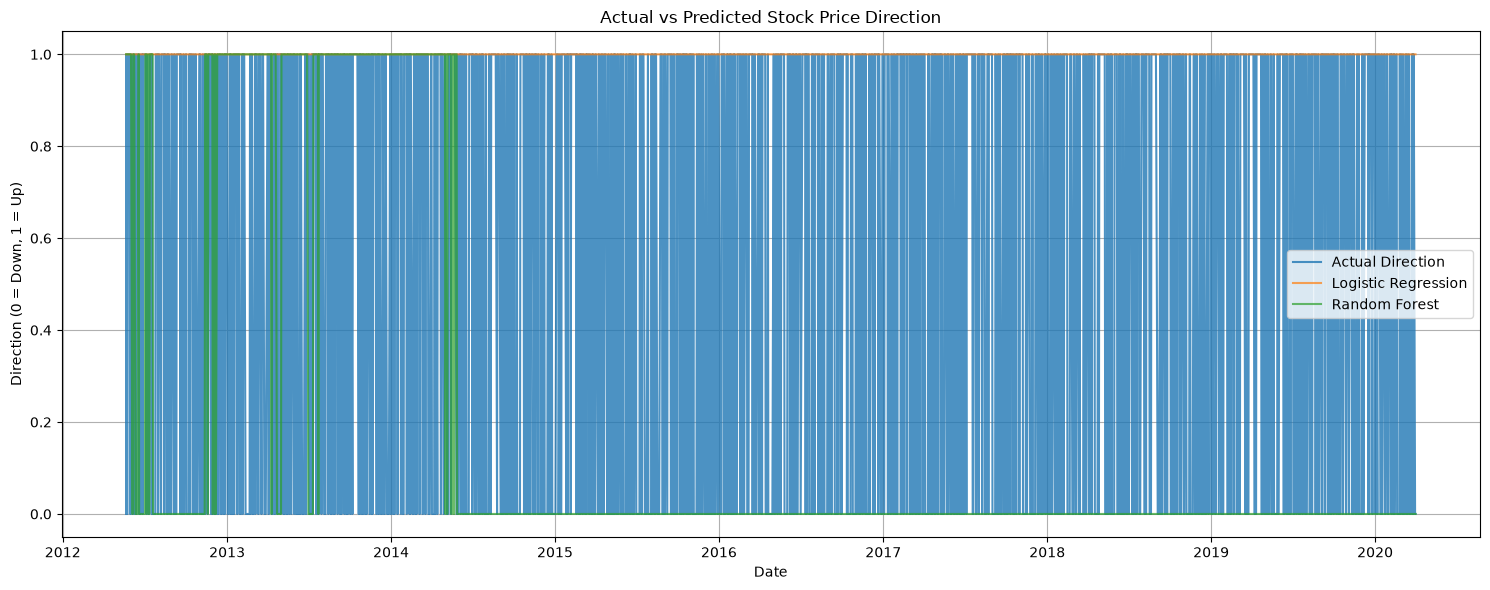

In [81]:
plt.figure(figsize=(15, 6))

plt.plot(
    comparison["Date"],
    comparison["Actual"],
    label="Actual Direction",
    alpha=0.8
)

plt.plot(
    comparison["Date"],
    comparison["Logistic Regression"],
    label="Logistic Regression",
    alpha=0.7
)

plt.plot(
    comparison["Date"],
    comparison["Random Forest"],
    label="Random Forest",
    alpha=0.7
)

plt.title("Actual vs Predicted Stock Price Direction")
plt.xlabel("Date")
plt.ylabel("Direction (0 = Down, 1 = Up)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [82]:
import numpy as np

In [83]:
df["Return_1"] = df["Close"].pct_change()
df["Return_2"] = df["Close"].pct_change(2)
df["Return_5"] = df["Close"].pct_change(5)

In [84]:
df["MA_Ratio_5"] = df["Close"] / df["MA_5"] - 1
df["MA_Ratio_10"] = df["Close"] / df["MA_10"] - 1
df["MA_Ratio_20"] = df["Close"] / df["MA_20"] - 1

In [85]:
df["Volatility_10"] = df["Return_1"].rolling(10).std()

In [86]:
df["Volume_Change"] = df["Volume"].pct_change()

In [87]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [88]:
df[[
    "Date", "Return_1", "Return_2", "Return_5",
    "MA_Ratio_5", "MA_Ratio_10", "MA_Ratio_20",
    "Volatility_10", "Volume_Change", "RSI_14"
]].tail()

,Date,Return_1,Return_2,Return_5,MA_Ratio_5,MA_Ratio_10,MA_Ratio_20,Volatility_10,Volume_Change,RSI_14
9904,2020-03-26,0.052623,0.046824,0.055805,0.072855,0.046765,-0.022965,0.074841,-0.169679,43.065694
9905,2020-03-27,-0.041402,0.009042,0.080701,0.012879,0.015865,-0.058858,0.064368,-0.189896,45.578425
9906,2020-03-30,0.028538,-0.014046,0.135669,0.016483,0.039485,-0.023842,0.049538,-0.177460,42.224034
9907,2020-03-31,-0.002041,0.026439,0.030015,0.008447,0.036759,-0.019253,0.047741,0.172796,44.345175
9908,2020-04-01,-0.052617,-0.054550,-0.018776,-0.041108,-0.015480,-0.059645,0.050212,-0.107497,47.885617


In [89]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

In [90]:
new_features = [
    "Return_1", "Return_2", "Return_5",
    "MA_Ratio_5", "MA_Ratio_10", "MA_Ratio_20",
    "Volatility_10", "Volume_Change", "RSI_14"]

In [91]:
improved_df = df.dropna(
    subset=new_features + ["Target"]
).copy()

X_new = improved_df[new_features]
y_new = improved_df["Target"].astype(int)


In [92]:
split_new = int(len(improved_df) * 0.80)

X_train_new = X_new.iloc[:split_new]
X_test_new = X_new.iloc[split_new:]
y_train_new = y_new.iloc[:split_new]
y_test_new = y_new.iloc[split_new:]

In [93]:
lr_new = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
lr_new.fit(X_train_new, y_train_new)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Return_1','Return_2','Return_5',...,'Volatility_10','Volume_Change', 'RSI_14']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [94]:
rf_new = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_new.fit(X_train_new, y_train_new)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [95]:
new_results = []

for name, model in [
    ("Improved Logistic Regression", lr_new),
    ("Improved Random Forest", rf_new)
]:
    pred = model.predict(X_test_new)
    prob = model.predict_proba(X_test_new)[:, 1]

    new_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_new, pred),
        "F1 Score": f1_score(y_test_new, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_new, prob)
    })

display(pd.DataFrame(new_results).round(4))

,Model,Accuracy,F1 Score,ROC-AUC
0,Improved Logistic Regression,0.5066,0.5197,0.5041
1,Improved Random Forest,0.5005,0.4995,0.5166


In [96]:
final_comparison = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "F1 Score": f1_score(y_test, y_pred_lr, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, logistic_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Baseline Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "F1 Score": f1_score(y_test, y_pred_rf, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, random_forest_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Improved Logistic Regression",
        "Accuracy": accuracy_score(
            y_test_new, lr_new.predict(X_test_new)
        ),
        "F1 Score": f1_score(
            y_test_new, lr_new.predict(X_test_new), zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test_new, lr_new.predict_proba(X_test_new)[:, 1]
        )
    },
    {
        "Model": "Improved Random Forest",
        "Accuracy": accuracy_score(
            y_test_new, rf_new.predict(X_test_new)
        ),
        "F1 Score": f1_score(
            y_test_new, rf_new.predict(X_test_new), zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test_new, rf_new.predict_proba(X_test_new)[:, 1]
        )
    }
])

display(final_comparison.round(4))

,Model,Accuracy,F1 Score,ROC-AUC
0,Baseline Logistic Regression,0.5207,0.6848,0.5125
1,Baseline Random Forest,0.4772,0.2646,0.5010
2,Improved Logistic Regression,0.5066,0.5197,0.5041
3,Improved Random Forest,0.5005,0.4995,0.5166


In [97]:
df.to_csv("stock_market_features.csv", index=False)

In [98]:
final_comparison.to_csv("model_comparison.csv", index=False)

In [99]:
prediction_output = pd.DataFrame({
    "Date": improved_df["Date"].iloc[split_new:].to_numpy(),
    "Actual_Direction": y_test_new.to_numpy(),
    "Predicted_Direction": rf_new.predict(X_test_new)
})

prediction_output.to_csv("stock_predictions.csv", index=False)

print("Files saved successfully:")
print("1. stock_market_features.csv")
print("2. model_comparison.csv")
print("3. stock_predictions.csv")

Files saved successfully:
1. stock_market_features.csv
2. model_comparison.csv
3. stock_predictions.csv


In [100]:
import joblib

joblib.dump(lr_new, "improved_logistic_model.joblib")
joblib.dump(rf_new, "improved_random_forest_model.joblib")

print("Both trained models saved successfully!")

Both trained models saved successfully!


In [101]:
import os

for file in os.listdir():
    if file.endswith((".csv", ".joblib")):
        print(file)

improved_logistic_model.joblib
improved_random_forest_model.joblib
model_comparison.csv
stock_market_features.csv
stock_predictions.csv
